# Inteligencia Artificial - Tarea 3
**Estudiantes:** Daniel Quintero, Jean Villasmil 

**Profesor:** Tomas Santana  

**Fecha:** 9 de Octubre 2026  

**Dataset seleccionado:** *Online Shoppers Purchasing Intention Dataset*

**Link:** https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset

**Fuente del Dataset:** Datos de comercio electrónico que registran 12,330 sesiones de usuarios en un sitio web de ventas online durante un período de un año, *Repositorio de Aprendizaje Automático de la Universidad de California en Irvine (UCI)*

## 1. Kernel Cuadrático
Dado el kernel cuadrático con $c=9$ y $x, z \in \mathbb{R}^2$:$$K(x, z) = (x^T z + c)^2 = \phi(x)^T \phi(z)$$

In [1]:
import numpy as np

# Definir los parámetros y vectores dados en el enunciado
c = 9.0
x = np.array([2.0, -3.0])
z = np.array([1.0, 4.0])

# 1. Definir la función de transformación phi(x) para el kernel cuadrático (c=9, x in R^2)
# phi(x) = [x1^2, x2^2, sqrt(2*c)*x1, sqrt(2*c)*x2, sqrt(2)*x1*x2, c]
def phi(v, c=9.0):
    v1, v2 = v[0], v[1]
    return np.array([
        v1**2,
        v2**2,
        np.sqrt(2 * c) * v1,
        np.sqrt(2 * c) * v2,
        np.sqrt(2) * v1 * v2,
        c
    ])

# 2. Obtener la transformación phi para x = [2, -3]^T
phi_x = phi(x, c)
print("--- RESULTADO ---")
print(f"phi([2, -3]^T) = {phi_x}\n")

# 3. Calcular el producto escalar en el espacio de características: phi(x)^T * phi(z)
phi_z = phi(z, c)
dot_product = np.dot(phi_x, phi_z)

# 4. Calcular directamente usando la función del kernel: K(x, z) = (x^T * z + c)^2
K_xz = (np.dot(x, z) + c)**2

print(f"Producto escalar phi(x)^T * phi(z): {dot_product}")
print(f"Evaluación directa K(x, z):         {K_xz}")

# 5. Verificar con np.isclose que coinciden numéricamente
coinciden = np.isclose(dot_product, K_xz)
print(f"\n¿Coinciden exactamente?: {coinciden}")

--- RESULTADO ---
phi([2, -3]^T) = [  4.           9.           8.48528137 -12.72792206  -8.48528137
   9.        ]

Producto escalar phi(x)^T * phi(z): 1.0000000000000284
Evaluación directa K(x, z):         1.0

¿Coinciden exactamente?: True


**Número de componentes de $\phi(x)$:**
Para un espacio de entrada de dimensión $d$, el kernel cuadrático $K(x, z) = (x^T z + c)^2$ genera una expansión polinómica de grado 2 que contiene:
- $d$ términos cuadráticos ($x_i^2$).
- $\binom{d}{2} = \frac{d(d-1)}{2}$ términos de interacción cruzada ($x_i x_j$).
- $d$ términos lineales ($x_i$).
- $1$ término constante ($c$).
Sumando todos estos términos, el vector $\phi(x)$ tiene un total de $\frac{d(d+3)}{2} + 1$ componentes, lo cual es del orden de $\mathcal{O}(d^2)$.

**Costo de calcular $\phi(x)^T \phi(z)$ directamente:**
Como los vectores transformados tienen una dimensión del orden de $\mathcal{O}(d^2)$, calcular explícitamente ambas transformaciones y luego realizar su producto escalar cuesta del orden de $\mathcal{O}(d^2)$ operaciones.

**Costo de calcular $K(x, z)$:**
Utilizando la función del kernel directamente como $K(x, z) = (x^T z + c)^2$, solo se requiere calcular el producto punto de los vectores originales de dimensión $d$ ($x^T z$), sumarle la constante $c$ y elevar al cuadrado. Esto cuesta del orden de $\mathcal{O}(d)$ operaciones.

## 2. SVC con kernel gaussiano y GridSearchCV

--- PROPORCIÓN DE CLASES ---
Revenue
0    0.8453
1    0.1547
Name: proportion, dtype: float64


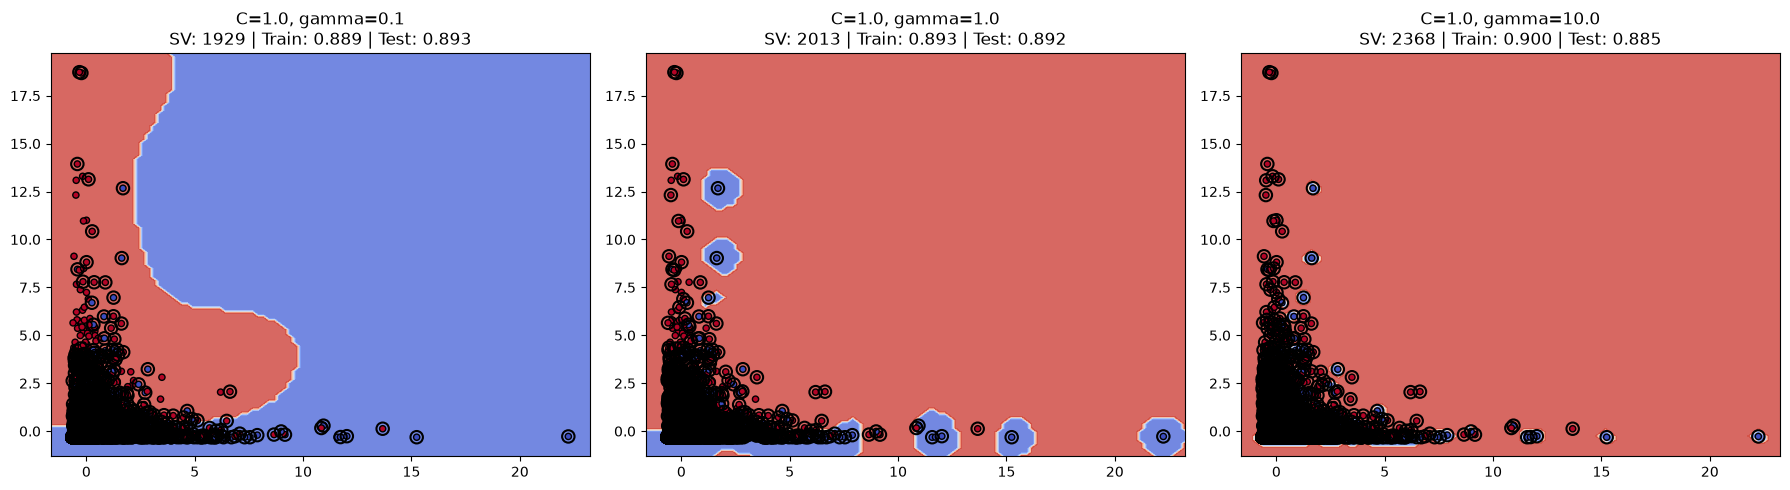

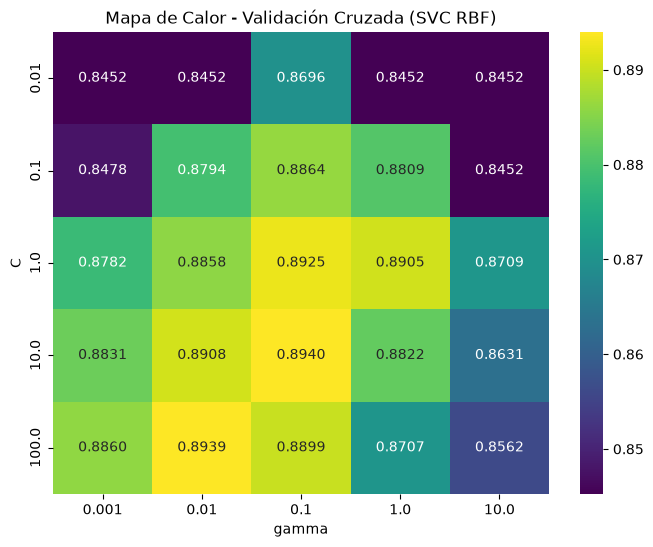

Mejor Score SVC en Prueba: 0.8930


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay

# Cargar y preparar el dataset (10,000 muestras)
df_raw = pd.read_csv('online_shoppers_intention.csv')
df = df_raw.sample(n=10000, random_state=42).reset_index(drop=True)

features_cuantitativas = [
    'Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration', 
    'BounceRates', 'ExitRates', 'PageValues', 'Administrative', 'ProductRelated'
]
target = 'Revenue'

X = df[features_cuantitativas]
y = df[target].astype(int)

print("--- PROPORCIÓN DE CLASES ---")
print(y.value_counts(normalize=True))

# Separar conjunto de prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Visualización con 2 features ('ProductRelated_Duration' y 'PageValues')
features_2d = ['ProductRelated_Duration', 'PageValues']
scaler_2d = StandardScaler()
X_train_2d = scaler_2d.fit_transform(X_train[features_2d])
X_test_2d = scaler_2d.transform(X_test[features_2d])

gammas = [0.1, 1.0, 10.0]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, g in enumerate(gammas):
    clf = SVC(kernel='rbf', C=1.0, gamma=g).fit(X_train_2d, y_train)
    DecisionBoundaryDisplay.from_estimator(
        clf, X_train_2d, response_method="predict", ax=axes[i], cmap=plt.cm.coolwarm, alpha=0.8
    )
    axes[i].scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, cmap=plt.cm.coolwarm, edgecolors='k', s=20)
    sv = clf.support_vectors_
    axes[i].scatter(sv[:, 0], sv[:, 1], s=80, facecolors='none', edgecolors='k', linewidths=1.5)
    train_acc = clf.score(X_train_2d, y_train)
    test_acc = clf.score(X_test_2d, y_test)
    axes[i].set_title(f"C=1.0, gamma={g}\nSV: {len(sv)} | Train: {train_acc:.3f} | Test: {test_acc:.3f}")

plt.tight_layout()
plt.show()

# Pipeline completo y GridSearchCV para SVC con todas las features
pipe_svc = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='rbf'))
])

param_grid_svc = {
    'svc__C': np.logspace(-2, 2, 5),
    'svc__gamma': np.logspace(-3, 1, 5)
}

grid_svc = GridSearchCV(pipe_svc, param_grid_svc, cv=5, scoring='accuracy', n_jobs=-1)
grid_svc.fit(X_train, y_train)

# Mapa de calor de validación cruzada
scores_matrix = grid_svc.cv_results_['mean_test_score'].reshape(len(param_grid_svc['svc__C']), len(param_grid_svc['svc__gamma']))
plt.figure(figsize=(8, 6))
sns.heatmap(scores_matrix, annot=True, fmt=".4f", 
            xticklabels=np.logspace(-3, 1, 5), 
            yticklabels=np.logspace(-2, 2, 5), cmap='viridis')
plt.xlabel('gamma')
plt.ylabel('C')
plt.title('Mapa de Calor - Validación Cruzada (SVC RBF)')
plt.show()

best_svc = grid_svc.best_estimator_
score_svc_test = best_svc.score(X_test, y_test)
print(f"Mejor Score SVC en Prueba: {score_svc_test:.4f}")

## 3. Árbol de Decisión y Random Forest

Mejor max_depth para el Árbol: 5


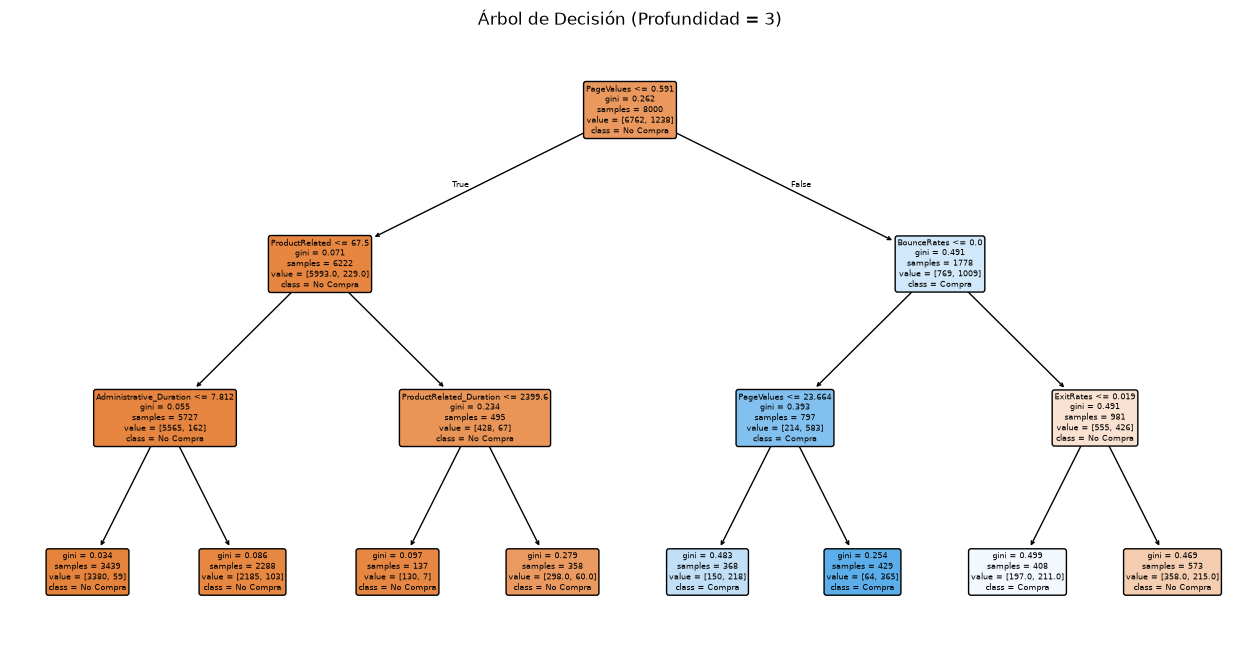

Mejores hiperparámetros para Random Forest: {'max_depth': 6, 'max_features': 'sqrt', 'n_estimators': 200}

Score de Prueba - Árbol de Decisión: 0.8880
Score de Prueba - Random Forest: 0.8920


In [3]:

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# GridSearchCV para Decision Tree
param_grid_dt = {'max_depth': range(1, 15)}
grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_dt, cv=5, scoring='accuracy')
grid_dt.fit(X_train, y_train)
best_dt = grid_dt.best_estimator_
print(f"Mejor max_depth para el Árbol: {grid_dt.best_params_['max_depth']}")

# Dibujar árbol de profundidad 3
plt.figure(figsize=(16, 8))
dt_p3 = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
plot_tree(dt_p3, feature_names=features_cuantitativas, class_names=['No Compra', 'Compra'], filled=True, rounded=True)
plt.title("Árbol de Decisión (Profundidad = 3)")
plt.show()

# GridSearchCV para Random Forest
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 6, 10],
    'max_features': ['sqrt', 0.5]
}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X_train, y_train)
best_rf = grid_rf.best_estimator_
print(f"Mejores hiperparámetros para Random Forest: {grid_rf.best_params_}")

# Reportar score de prueba de ambos modelos
score_dt_test = best_dt.score(X_test, y_test)
score_rf_test = best_rf.score(X_test, y_test)
print(f"\nScore de Prueba - Árbol de Decisión: {score_dt_test:.4f}")
print(f"Score de Prueba - Random Forest: {score_rf_test:.4f}")

## 4. Evaluación, Comparación y Matrices de Confusión


================ REPORTE DE CLASIFICACIÓN (SVC) ================
              precision    recall  f1-score   support

   No Compra       0.92      0.96      0.94      1691
      Compra       0.71      0.52      0.60       309

    accuracy                           0.89      2000
   macro avg       0.81      0.74      0.77      2000
weighted avg       0.88      0.89      0.89      2000


================ REPORTE DE CLASIFICACIÓN (Árbol de Decisión) ================
              precision    recall  f1-score   support

   No Compra       0.91      0.96      0.94      1691
      Compra       0.69      0.49      0.58       309

    accuracy                           0.89      2000
   macro avg       0.80      0.73      0.76      2000
weighted avg       0.88      0.89      0.88      2000


================ REPORTE DE CLASIFICACIÓN (Random Forest) ================
              precision    recall  f1-score   support

   No Compra       0.91      0.97      0.94      1691
      Compra   

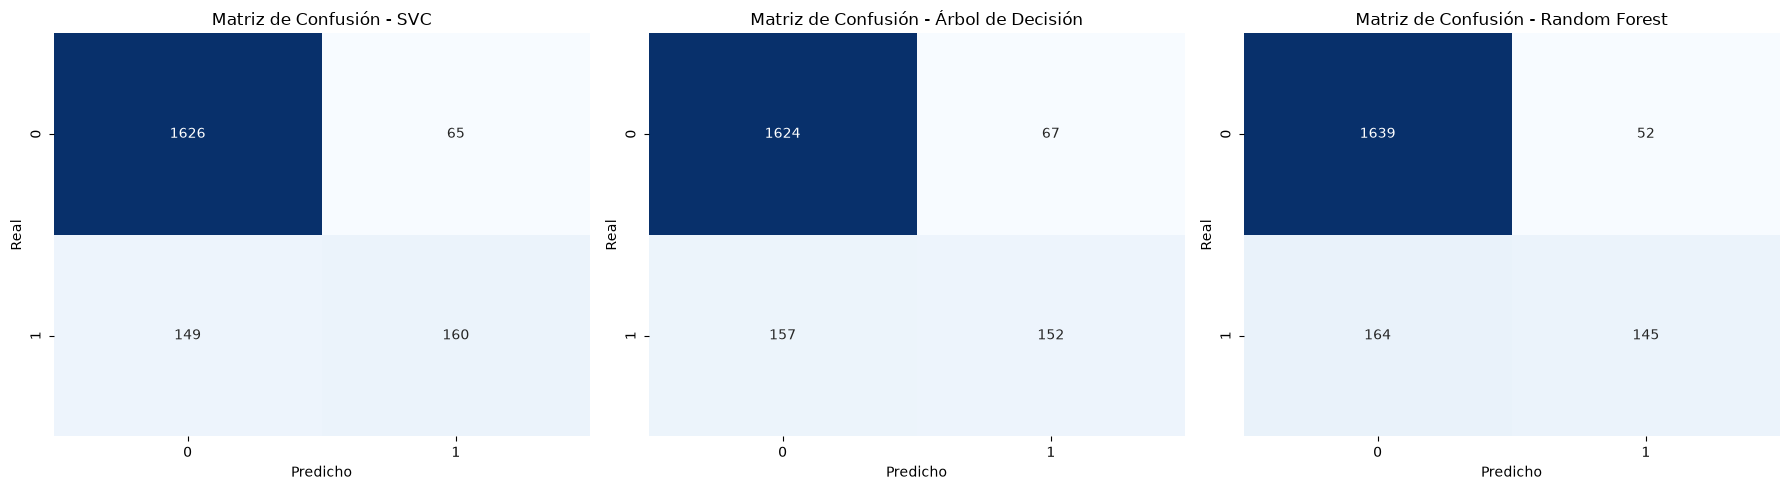

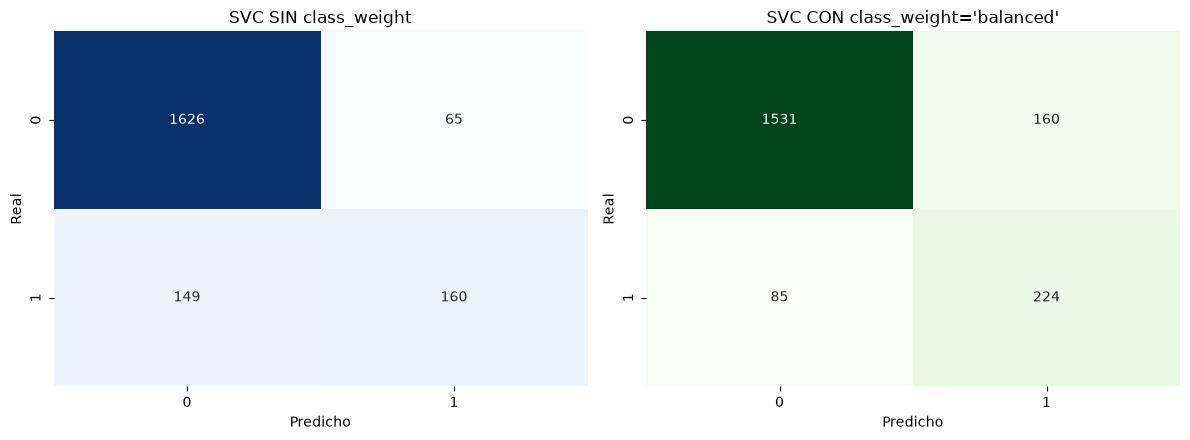


================ REPORTE SVC CON class_weight='balanced' ================
              precision    recall  f1-score   support

   No Compra       0.95      0.91      0.93      1691
      Compra       0.58      0.72      0.65       309

    accuracy                           0.88      2000
   macro avg       0.77      0.82      0.79      2000
weighted avg       0.89      0.88      0.88      2000



In [9]:
from sklearn.metrics import confusion_matrix, classification_report

models = {
    'SVC': best_svc, 
    'Árbol de Decisión': best_dt, 
    'Random Forest': best_rf
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', ax=axes[i], cmap='Blues', cbar=False)
    axes[i].set_title(f"Matriz de Confusión - {name}")
    axes[i].set_xlabel("Predicho")
    axes[i].set_ylabel("Real")
    
    print(f"\n================ REPORTE DE CLASIFICACIÓN ({name}) ================")
    print(classification_report(y_test, y_pred, target_names=['No Compra', 'Compra'], digits=2))

plt.tight_layout()
plt.show()

# Experimento con class_weight='balanced' en SVC
pipe_svc_balanced = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='rbf', C=10.0, gamma=0.01, class_weight='balanced', random_state=42))
])
pipe_svc_balanced.fit(X_train, y_train)
y_pred_balanced = pipe_svc_balanced.predict(X_test)

cm_balanced = confusion_matrix(y_test, y_pred_balanced)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Comparación gráfica de Matrices de Confusión
sns.heatmap(confusion_matrix(y_test, best_svc.predict(X_test)), annot=True, fmt='d', ax=axes[0], cmap='Blues', cbar=False)
axes[0].set_title("SVC SIN class_weight")
axes[0].set_xlabel("Predicho")
axes[0].set_ylabel("Real")

sns.heatmap(cm_balanced, annot=True, fmt='d', ax=axes[1], cmap='Greens', cbar=False)
axes[1].set_title("SVC CON class_weight='balanced'")
axes[1].set_xlabel("Predicho")
axes[1].set_ylabel("Real")

plt.tight_layout()
plt.show()

print("\n================ REPORTE SVC CON class_weight='balanced' ================")
print(classification_report(y_test, y_pred_balanced, target_names=['No Compra', 'Compra'], digits=2))

### **¿Por qué la exactitud (Accuracy) por defecto puede no ser óptima y si lo es o no para el dataset?**
- **Por qué no es óptima en general:** La exactitud mide el total de aciertos globales entre el total de muestras. Si un dataset está fuertemente desbalanceado (como el nuestro, donde el ~84.5% de las sesiones son No Compra y solo el ~15.5% son Compra), un modelo perezoso que prediga siempre la clase mayoritaria obtendría una exactitud del 84.5% sin aprender absolutamente nada útil.

- **Si lo es o no para el dataset:** Para nuestro dataset en particular (Online Shoppers Purchasing Intention), la exactitud no es del todo óptima, ya que el desbalance de clases hace que los modelos ignoren parcialmente a los compradores reales (reflejado en un recall bajo para la clase de compra). Sería preferible utilizar métricas como el `F1-Score`, el `ROC-AUC` o el `Recall` de la clase positiva para penalizar el hecho de dejar ir a clientes potenciales.

### **Comparación entre SVC y Random Forest (Ventajas y Desventajas)**
_SVC (con kernel RBF):_
- Ventajas: Excelente para encontrar fronteras de decisión no lineales complejas en espacios de características transformados; muy potente cuando el margen óptimo de separación está bien definido.
- Desventajas: Sensible a la escala de los datos (exige obligatorio usar StandardScaler dentro de un Pipeline); es una "caja negra" difícil de interpretar visualmente; y su costo computacional escala fuertemente con el número de muestras ($\mathcal{O}(N^2)$ a $\mathcal{O}(N^3)$), haciéndolo lento en entrenamiento con datasets grandes.

_Random Forest:_
- Ventajas: Es totalmente invariante a la escala de las características (no requiere estandarización); maneja de forma natural interacciones complejas y variables mixtas; ofrece métricas claras de importancia de características (feature importances); y es altamente paralelizable.
- Desventajas: Tiende a sobreajustar si no se limitan adecuadamente hiperparámetros como max_depth o min_samples_split; sus árboles individuales son inestables ante pequeños cambios en los datos de entrenamiento (aunque el ensamblaje lo mitiga).

### **Uso de `class_weight` (Explicación y Comparación de Resultados)**
- Qué hace: Soluciona el desbalance del dataset (84.5% No Compra vs. 15.5% Compra) ajustando pesos inversamente proporcionales a la frecuencia de cada clase. Castiga con mayor severidad los errores cometidos en la clase minoritaria (Compra), obligando al modelo a prestarle atención en lugar de ignorarla.

- ¿Cómo cambió los resultados en el SVC?
    - _Sensibilidad (Recall) disparada:_ Subió del $52\%$ al $72\%$ en la clase Compra. Esto significa que el modelo logró rescatar a 64 compradores reales adicionales que antes se perdían (reduciendo los Falsos Negativos de 149 a 85).
    - _Exactitud estable:_ La exactitud global (accuracy) se mantuvo sólida en $88\%$ (prácticamente igual al 89% inicial).
    - _Mejora del F1-Score:_ El balance general para la clase de interés mejoró de $0.56$ a $0.65$.
    - _El costo:_ Aumentaron levemente los Falsos Positivos (usuarios catalogados como compradores que no concretaron), lo que redujo un poco la precisión individual de esa clase, pero logrando un modelo comercialmente mucho más útil y realista.